# SepsisShield — Person 1: Exploratory Data Analysis (EDA)

### NIErnaya 2026 | Phase 2 | Data Analytics and Visualization

**Responsibility:** Dataset understanding, data-quality investigation, missing-value analysis, duplicates, outliers, distributions, correlations, visualisations and evidence-based findings.

---

## What makes this EDA different?

Instead of showing charts without interpretation, this notebook asks a sequence of questions about the ICU dataset. It also includes three project-specific views:

1. **Two ways to measure sepsis frequency:** hourly records versus unique patients. These answer different questions.
2. **Measurement-availability fingerprint:** how often measurements are recorded across the patient cohort, not just how many cells are missing.
3. **Timeline around the first positive SepsisLabel hour:** a simple cohort view of how selected measurements behave around the first recorded warning label.

**Important:** `SepsisLabel` is the dataset's early-warning label. The first positive label hour is not the exact clinical onset time. This analysis is retrospective research, not a diagnostic tool.

### Libraries used

Only the familiar libraries from the DAV course reference notebooks are used: **Pandas, NumPy, Matplotlib and Seaborn**. The outlier section uses the IQR method covered in the lab material.

## 1. Import the required libraries

We use Pandas for tables and analysis, NumPy for numerical operations, Matplotlib and Seaborn for charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load the Sepsis dataset

**Question:** What data are we analysing?

Place the original `Dataset.csv` inside a folder named `data` next to this notebook, or keep it in the same folder as the notebook. If it is somewhere else, enter its full path when asked.

In [2]:
# Load the dataset from the same folder as this notebook

df = pd.read_csv("Dataset.csv", low_memory=False)

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully
Rows: 1552210
Columns: 44


## 3. Understand the dataset structure

**Question:** How large is the dataset, what does one row represent, and what variables are available?

Each row represents one hourly observation for one ICU patient. `Patient_ID` identifies the patient, `Hour` gives the hour in that patient's record, and `SepsisLabel` is the target label supplied with the dataset.

In [3]:
print("First five records")
display(df.head())

print("Dataset shape:", df.shape)
print("Number of unique patients:", df["Patient_ID"].nunique())

print("\nColumn names")
print(df.columns.tolist())

print("\nData types")
print(df.dtypes)

First five records


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,17072
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,17072
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,17072
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,17072
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,...,NaN,330.0,68.54,0,NaN,NaN,-0.02,5,0,17072


Dataset shape: (1552210, 44)
Number of unique patients: 40336

Column names
['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID']

Data types
Unnamed: 0            int64
Hour                  int64
HR                  float64
O2Sat               float64
Temp                float64
SBP                 float64
MAP                 float64
DBP                 float64
Resp                float64
EtCO2               float64
BaseExcess          float64
HCO3                float64
FiO2                float64
pH                  float64
PaCO2               float64
SaO2                float64
AST

In [4]:
# Summary of numerical columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1552210.0,25.492745,28.882557,0.00,9.00,19.000,33.00,335.00
Hour,1552210.0,25.492745,28.882557,0.00,9.00,19.000,33.00,335.00
HR,1398811.0,84.581443,17.325242,20.00,72.00,83.500,95.50,280.00
O2Sat,1349474.0,97.193955,2.936924,20.00,96.00,98.000,99.50,100.00
Temp,525226.0,36.977228,0.770014,20.90,36.50,37.000,37.50,50.00
SBP,1325945.0,123.750465,23.231556,20.00,107.00,121.000,138.00,300.00
MAP,1358940.0,82.400100,16.341750,20.00,71.00,80.000,92.00,300.00
DBP,1065656.0,63.830556,13.956010,20.00,54.00,62.000,72.00,300.00
Resp,1313875.0,18.726498,5.098194,1.00,15.00,18.000,21.50,100.00
EtCO2,57636.0,32.957657,7.951662,10.00,28.00,33.000,38.00,100.00


### 3.1 Understand the variable groups

The variables can be explained in four simple groups:

| Group | Examples | What they represent |
|---|---|---|
| Vital signs | HR, O2Sat, Temp, SBP, MAP, DBP, Resp, EtCO2 | Patient observations and vital measurements |
| Laboratory measurements | Lactate, Creatinine, Glucose, WBC, Platelets, etc. | Results from laboratory tests |
| Patient and ICU context | Age, Gender, Unit1, Unit2, HospAdmTime, ICULOS | Demographic and ICU-related information |
| Record identifiers and target | Patient_ID, Hour, SepsisLabel | Patient, time position and supplied outcome label |

`Unnamed: 0` is also present in this merged file. We will check whether it duplicates `Hour`; we will not treat it as a clinical measurement.

In [5]:
# Check whether the extra index column is an exact copy of Hour
if "Unnamed: 0" in df.columns and "Hour" in df.columns:
    same_as_hour = df["Unnamed: 0"].equals(df["Hour"])
    print("Does Unnamed: 0 exactly match Hour?", same_as_hour)
else:
    print("Unnamed: 0 or Hour column is not present")

Does Unnamed: 0 exactly match Hour? True


## 4. Check the target label: hourly records and patients

**Question:** How common is the positive sepsis warning label?

We report this in two ways:

- **Record level:** percentage of hourly rows with `SepsisLabel = 1`.
- **Patient level:** percentage of unique patients who have at least one positive label during their record.

These percentages are not expected to be equal because one patient can contribute many hourly rows.

In [6]:
print("Hourly record counts")
label_counts = df["SepsisLabel"].value_counts().sort_index()
print(label_counts)

record_percent = df["SepsisLabel"].value_counts(normalize=True).sort_index() * 100
print("\nHourly record percentages")
print(record_percent.round(2))

# One value per patient: 1 if that patient ever has a positive label
patient_label = df.groupby("Patient_ID")["SepsisLabel"].max()
patient_counts = patient_label.value_counts().sort_index()
patient_percent = patient_label.value_counts(normalize=True).sort_index() * 100

print("\nPatient counts by whether they ever had a positive label")
print(patient_counts)
print("\nPatient percentages")
print(patient_percent.round(2))

Hourly record counts
SepsisLabel
0    1524294
1      27916
Name: count, dtype: int64

Hourly record percentages
SepsisLabel
0    98.2
1     1.8
Name: proportion, dtype: float64

Patient counts by whether they ever had a positive label
SepsisLabel
0    37404
1     2932
Name: count, dtype: int64

Patient percentages
SepsisLabel
0    92.73
1     7.27
Name: proportion, dtype: float64


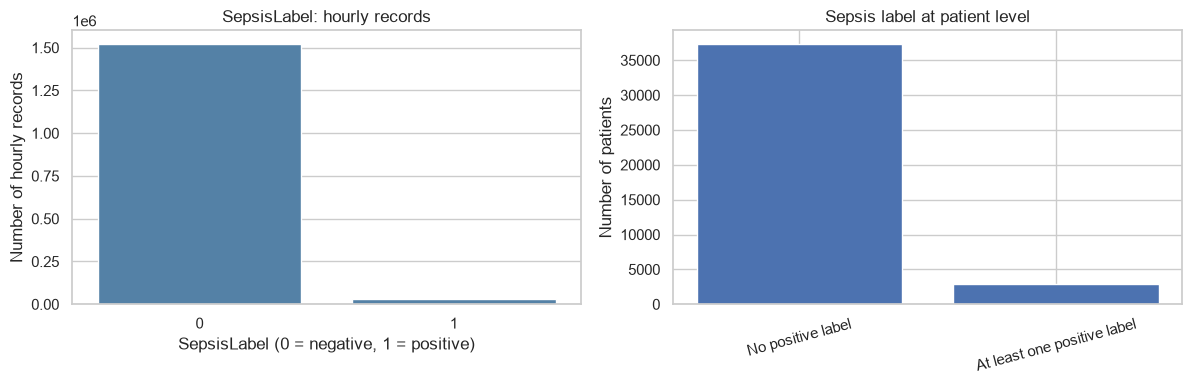

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x="SepsisLabel", data=df, ax=axes[0], color="steelblue")
axes[0].set_title("SepsisLabel: hourly records")
axes[0].set_xlabel("SepsisLabel (0 = negative, 1 = positive)")
axes[0].set_ylabel("Number of hourly records")

patient_plot = patient_label.value_counts().sort_index()
axes[1].bar(["No positive label", "At least one positive label"],
            [patient_plot.get(0, 0), patient_plot.get(1, 0)])
axes[1].set_title("Sepsis label at patient level")
axes[1].set_ylabel("Number of patients")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### How to explain this finding

A row-level percentage describes the proportion of recorded hours with a positive label. A patient-level percentage describes the proportion of patients who had at least one positive label. **Do not describe these as the same statistic.** The label distribution is also imbalanced, which is important context for later modelling and evaluation.

## 5. Check data quality: missing values

**Question:** Which variables are incomplete, and how large is the missingness?

We calculate both the number and percentage of missing cells in each column. We display the most-missing variables first.

In [8]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

missing_table = missing_table.sort_values(
    by="Missing_Percent", ascending=False
)

display(missing_table.head(20).round(2))

,Missing_Count,Missing_Percent
Bilirubin_direct,1549220,99.81
Fibrinogen,1541968,99.34
TroponinI,1537429,99.05
Bilirubin_total,1529069,98.51
Alkalinephos,1527269,98.39
AST,1527027,98.38
Lactate,1510764,97.33
PTT,1506511,97.06
SaO2,1498649,96.55
EtCO2,1494574,96.29


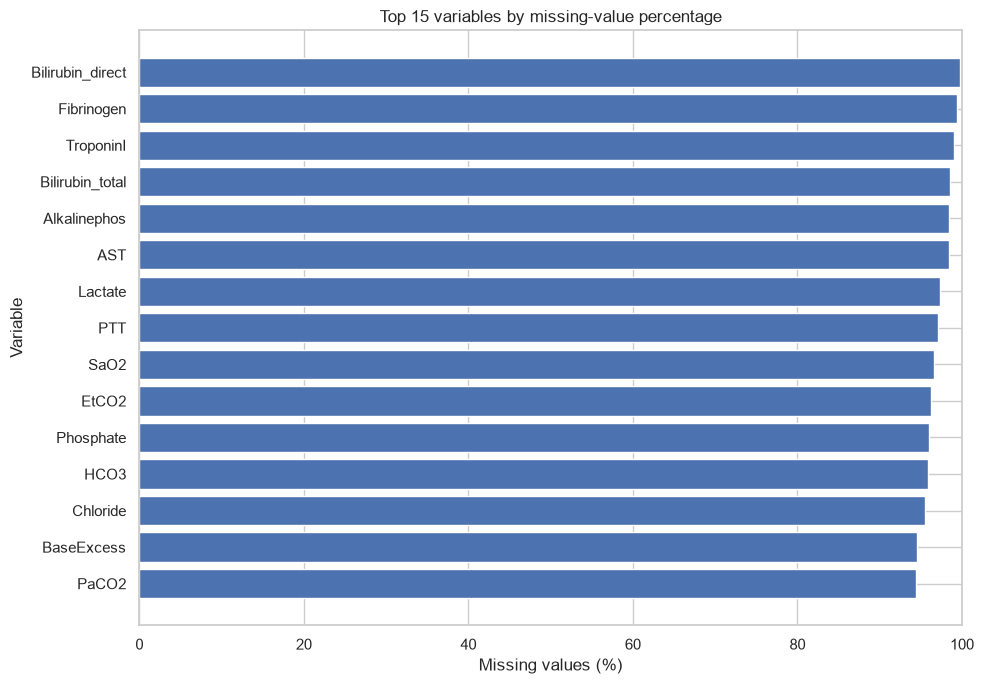

In [9]:
# Visualise the 15 variables with the highest missing percentage
top_missing = missing_table.head(15).sort_values("Missing_Percent")

plt.figure(figsize=(10, 7))
plt.barh(top_missing.index, top_missing["Missing_Percent"])
plt.xlabel("Missing values (%)")
plt.ylabel("Variable")
plt.title("Top 15 variables by missing-value percentage")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### 5.1 A more useful view: measurement availability across patients

A missing-value percentage counts empty cells. But in an ICU dataset, another useful question is: **For how many patients was a particular measurement recorded at least once?**

This is our first project-specific analysis. It helps distinguish measurements that are routinely recorded from tests that are only available for a smaller part of the cohort. It does not tell us why a clinician ordered or did not order a test.

In [10]:
# Selected vital signs and laboratory tests
availability_variables = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp",
    "Lactate", "Creatinine", "Glucose", "WBC", "Platelets",
    "Bilirubin_total", "TroponinI"
]

availability_variables = [col for col in availability_variables if col in df.columns]

# Count non-missing observations for each variable within each patient
patient_measurements = df.groupby("Patient_ID")[availability_variables].count()

# Percentage of patients who have at least one recorded measurement
patient_coverage = (patient_measurements > 0).mean() * 100

availability_table = pd.DataFrame({
    "Patients_with_at_least_one_measurement_percent": patient_coverage,
    "Rows_missing_percent": missing_percent[availability_variables]
})

availability_table = availability_table.sort_values(
    "Patients_with_at_least_one_measurement_percent", ascending=False
)

display(availability_table.round(2))

,Patients_with_at_least_one_measurement_percent,Rows_missing_percent
HR,99.99,9.88
O2Sat,99.96,13.06
Resp,99.82,15.35
MAP,99.74,12.45
SBP,99.30,14.58
Temp,99.30,66.16
Glucose,96.08,82.89
Creatinine,94.92,93.90
Platelets,93.61,94.06
WBC,93.49,93.59


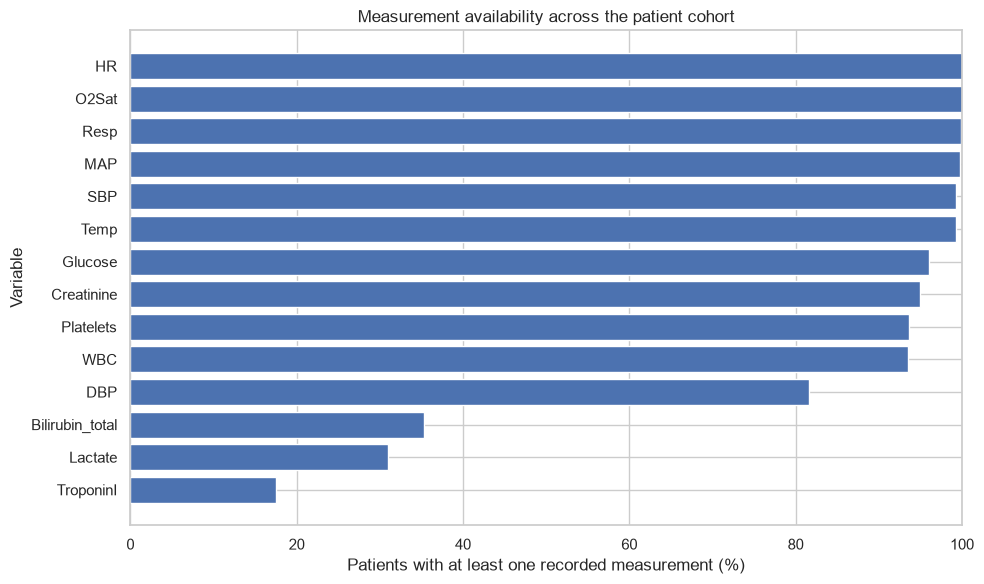

In [11]:
plt.figure(figsize=(10, 6))
coverage_plot = availability_table.sort_values(
    "Patients_with_at_least_one_measurement_percent"
)

plt.barh(
    coverage_plot.index,
    coverage_plot["Patients_with_at_least_one_measurement_percent"]
)
plt.xlabel("Patients with at least one recorded measurement (%)")
plt.ylabel("Variable")
plt.title("Measurement availability across the patient cohort")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### How to explain the availability fingerprint

“For each selected variable, we checked whether each patient had at least one recorded value. This tells us how widely the measurement appears across the cohort. Some laboratory measurements are much less widely available than vital signs. We therefore report missingness instead of assuming that an unrecorded test has a normal value.”

**Do not claim:** that a missing test proves a patient was healthy, that a test was unnecessary, or that missingness caused sepsis.

## 6. Check duplicate records

**Question:** Are there repeated rows or repeated patient-hour combinations?

We check two types:

1. Exact duplicate rows across all columns.
2. Duplicate combinations of `Patient_ID` and `Hour`.

The second check matters because each patient should have one record for a given hour in this merged dataset.

In [12]:
exact_duplicates = df.duplicated().sum()
patient_hour_duplicates = df.duplicated(subset=["Patient_ID", "Hour"]).sum()

print("Exact duplicate rows:", exact_duplicates)
print("Duplicate Patient_ID + Hour combinations:", patient_hour_duplicates)

Exact duplicate rows: 0
Duplicate Patient_ID + Hour combinations: 0


## 7. Check unusual values using the IQR method

**Question:** Do any selected vital-sign measurements fall unusually far from the middle 50% of their distribution?

The Interquartile Range (IQR) method uses:

- Q1: 25th percentile
- Q3: 75th percentile
- IQR = Q3 − Q1
- Lower limit = Q1 − 1.5 × IQR
- Upper limit = Q3 + 1.5 × IQR

These limits identify **statistical outlier candidates**. They do not automatically prove that a clinical measurement is wrong. We will flag and count them, not delete them in this EDA notebook.

In [13]:
vital_signs = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp"]
vital_signs = [col for col in vital_signs if col in df.columns]

iqr_results = []

for col in vital_signs:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()
    valid_count = df[col].notna().sum()
    outlier_percent = (outlier_count / valid_count) * 100 if valid_count > 0 else 0

    iqr_results.append({
        "Variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Outlier_Count": outlier_count,
        "Outlier_Percent_of_nonmissing": outlier_percent
    })

iqr_table = pd.DataFrame(iqr_results).set_index("Variable")
display(iqr_table.round(2))

,Q1,Q3,IQR,Lower_Limit,Upper_Limit,Outlier_Count,Outlier_Percent_of_nonmissing
Variable,,,,,,,
HR,72.0,95.5,23.5,36.75,130.75,14032,1.00
O2Sat,96.0,99.5,3.5,90.75,104.75,24782,1.84
Temp,36.5,37.5,1.0,35.00,39.00,6569,1.25
SBP,107.0,138.0,31.0,60.50,184.50,15842,1.19
MAP,71.0,92.0,21.0,39.50,123.50,21894,1.61
DBP,54.0,72.0,18.0,27.00,99.00,16296,1.53
Resp,15.0,21.5,6.5,5.25,31.25,27855,2.12


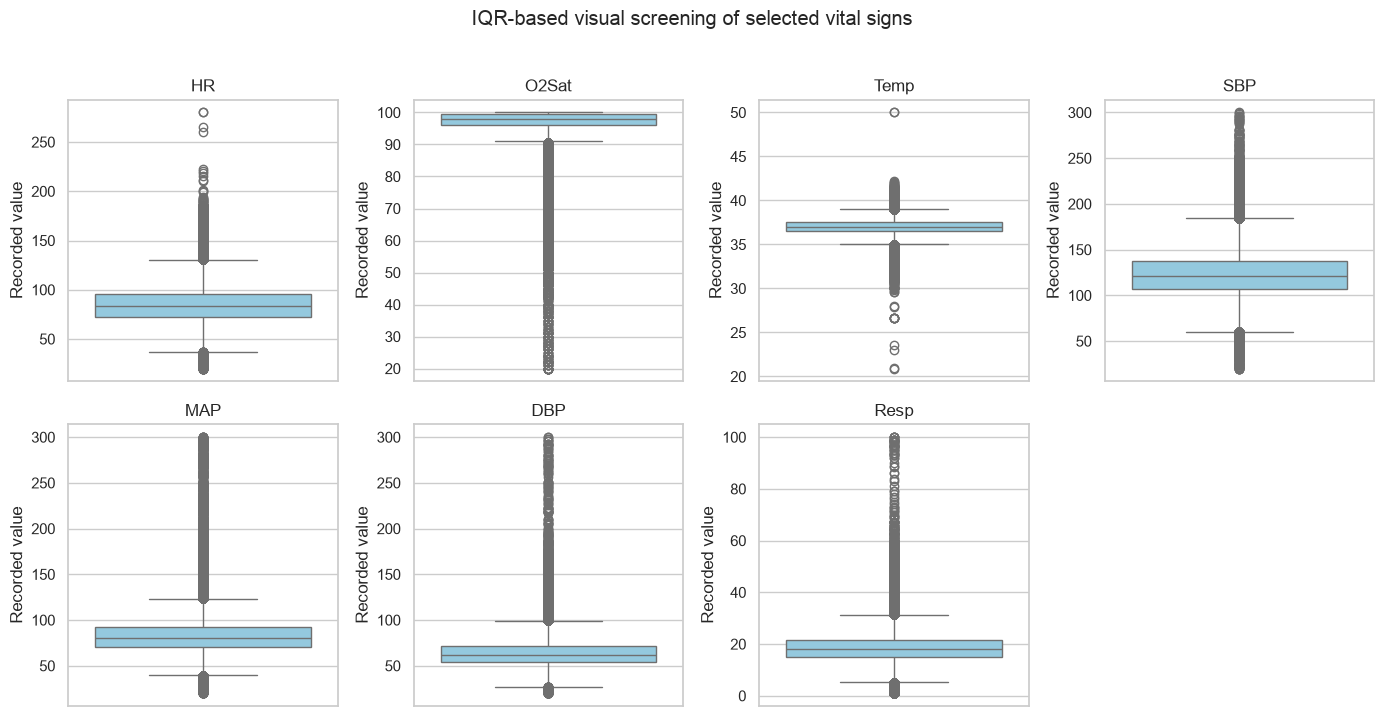

In [14]:
# Boxplots show the spread and possible outlier candidates
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, col in enumerate(vital_signs):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
    axes[i].set_title(col)
    axes[i].set_ylabel("Recorded value")

for j in range(len(vital_signs), len(axes)):
    axes[j].axis("off")

plt.suptitle("IQR-based visual screening of selected vital signs", y=1.02)
plt.tight_layout()
plt.show()

### How to explain the outlier result

“The IQR method marks values outside the usual statistical range. In clinical data, an unusual value may be a genuine extreme observation, a measurement issue, or a data-entry issue. Therefore, we use IQR for screening and do not automatically delete these records.”

## 8. Study distributions of important vital signs

**Question:** How are the main measurements distributed?

We use histograms to see where values are concentrated and whether the distributions are symmetric, skewed or spread out. To keep the charts quick to render, we use a random sample of up to 100,000 rows for visualisation only. All earlier count and missing-value calculations use the full dataset.

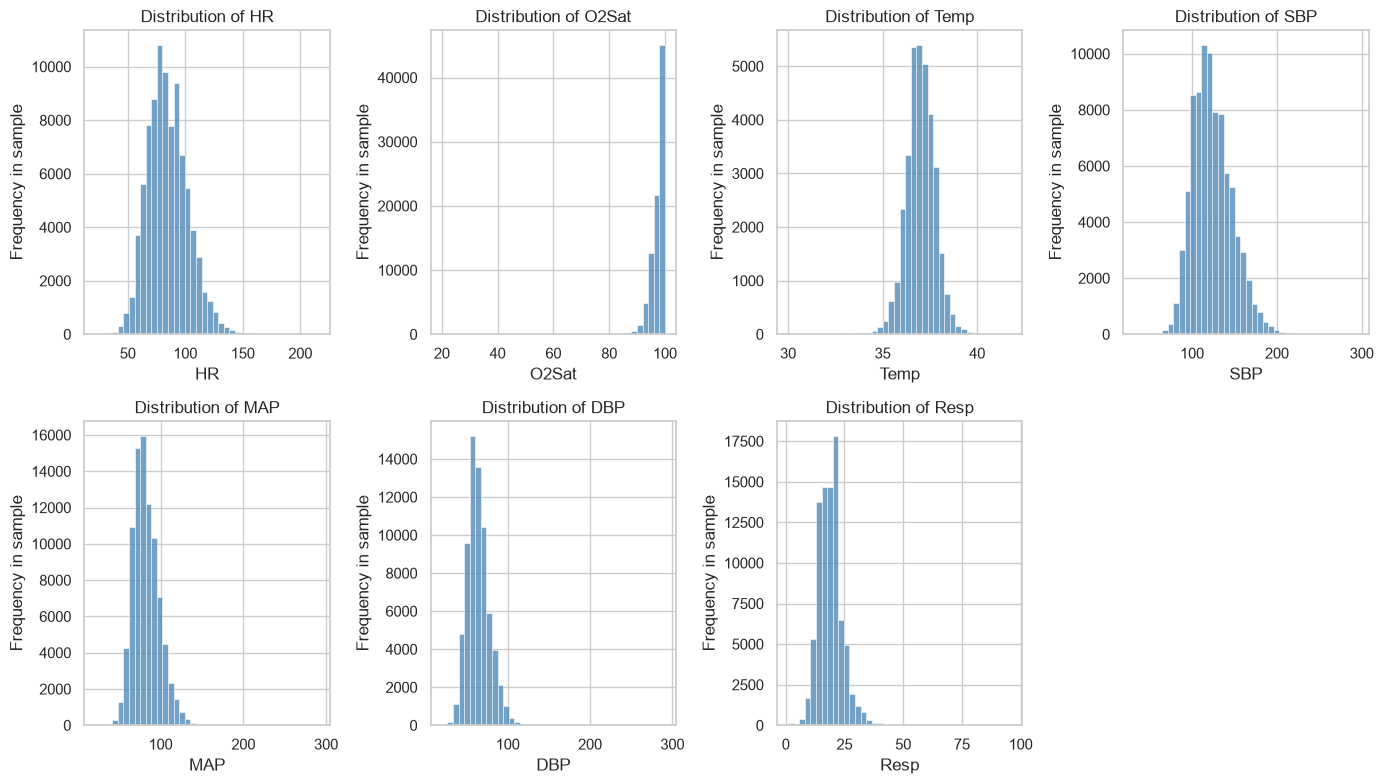

In [15]:
sample_size = min(100000, len(df))
plot_sample = df.sample(n=sample_size, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(vital_signs):
    sns.histplot(plot_sample[col].dropna(), bins=40, ax=axes[i], color="steelblue")
    axes[i].set_title("Distribution of " + col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency in sample")

for j in range(len(vital_signs), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## 9. Study correlations between vital signs

**Question:** Which selected measurements tend to vary together?

We use a Spearman correlation heatmap for the selected vital signs. Correlation describes an association between two variables; it does not show that one variable causes another. Pairwise available values are used by Pandas when calculating the correlation matrix.

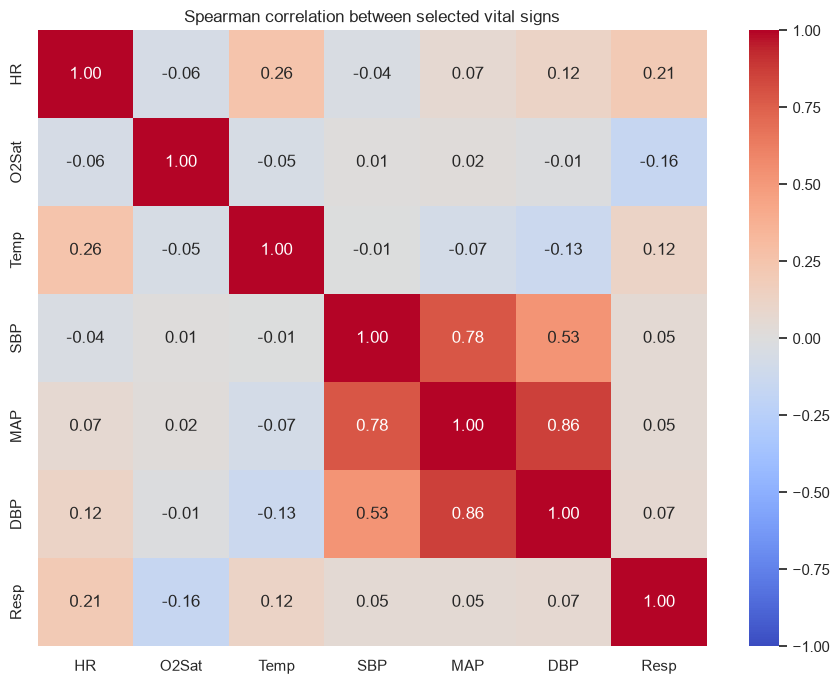

,HR,O2Sat,Temp,SBP,MAP,DBP,Resp
HR,1.00,-0.06,0.26,-0.04,0.07,0.12,0.21
O2Sat,-0.06,1.00,-0.05,0.01,0.02,-0.01,-0.16
Temp,0.26,-0.05,1.00,-0.01,-0.07,-0.13,0.12
SBP,-0.04,0.01,-0.01,1.00,0.78,0.53,0.05
MAP,0.07,0.02,-0.07,0.78,1.00,0.86,0.05
DBP,0.12,-0.01,-0.13,0.53,0.86,1.00,0.07
Resp,0.21,-0.16,0.12,0.05,0.05,0.07,1.00


In [16]:
correlation_data = df[vital_signs].sample(
    n=min(100000, len(df)), random_state=42
)

correlation_matrix = correlation_data.corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Spearman correlation between selected vital signs")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(2))

### How to explain the correlation chart

“Positive correlation means two measurements tend to increase together; negative correlation means one tends to increase as the other decreases. A value near zero indicates little monotonic association in this summary. This is an exploratory relationship, not evidence of cause and effect.”

## 10. Compare missingness between negative and positive label rows

**Question:** Does the percentage of missing measurements look different between rows with `SepsisLabel = 0` and `SepsisLabel = 1`?

This is a descriptive comparison only. It cannot tell us why a measurement is missing or establish a causal relationship.

Missing percentage by SepsisLabel


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp
SepsisLabel,,,,,,,
0,9.92,13.11,66.16,14.57,12.51,31.37,15.37
1,7.94,10.36,66.06,15.20,9.50,29.89,14.34


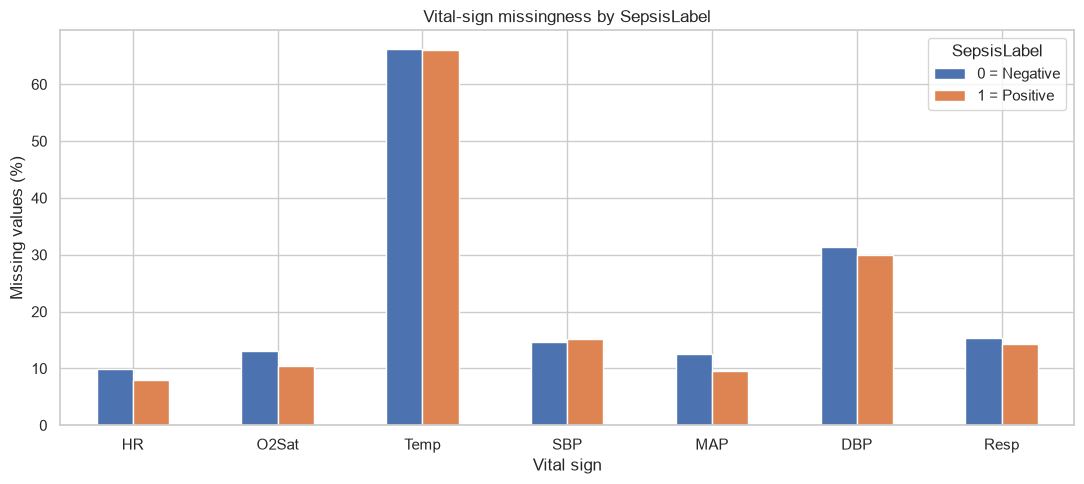

In [17]:
missing_by_label = df.groupby("SepsisLabel")[vital_signs].apply(
    lambda group: group.isnull().mean() * 100
)

print("Missing percentage by SepsisLabel")
display(missing_by_label.round(2))

missing_by_label.T.plot(kind="bar", figsize=(11, 5))
plt.ylabel("Missing values (%)")
plt.xlabel("Vital sign")
plt.title("Vital-sign missingness by SepsisLabel")
plt.xticks(rotation=0)
plt.legend(title="SepsisLabel", labels=["0 = Negative", "1 = Positive"])
plt.tight_layout()
plt.show()

## 11. A SepsisShield-specific view: measurements around the first positive warning label

**Question:** How do selected measurements look in the hours before and after a patient's first positive `SepsisLabel` hour?

For each patient who has a positive label, we find their first hour with `SepsisLabel = 1`. We then calculate a relative hour:

- `-6` means six hours before that first positive label hour.
- `0` means the first positive label hour.
- `+3` means three hours after that hour.

We plot the median HR, MAP and O2Sat at each relative hour, together with the number of available measurements.

**Interpretation caution:** this is aligned to the first recorded positive warning label, not to the exact clinical onset of sepsis. The label is already designed as an early-warning target. Different numbers of patients may contribute at different relative hours.

In [18]:
# Find the first positive label hour for each patient
first_positive_hour = (
    df[df["SepsisLabel"] == 1]
    .groupby("Patient_ID")["Hour"]
    .min()
)

# Keep records for patients who have at least one positive label
relative_df = df[df["Patient_ID"].isin(first_positive_hour.index)].copy()
relative_df["Relative_Hour"] = (
    relative_df["Hour"] - relative_df["Patient_ID"].map(first_positive_hour)
)

# Focus on a window from 12 hours before to 6 hours after the first positive label
relative_window = relative_df[
    (relative_df["Relative_Hour"] >= -12) &
    (relative_df["Relative_Hour"] <= 6)
]

trend_variables = [col for col in ["HR", "MAP", "O2Sat"] if col in df.columns]

median_trend = relative_window.groupby("Relative_Hour")[trend_variables].median()
measurement_counts = relative_window.groupby("Relative_Hour")[trend_variables].count()

print("Median measurements by relative hour")
display(median_trend.round(2))

print("\nNumber of available measurements contributing to each median")
display(measurement_counts)

Median measurements by relative hour


,HR,MAP,O2Sat
Relative_Hour,,,
-12,88.0,80.00,98.0
-11,88.0,80.00,98.0
-10,88.0,80.00,98.0
-9,88.0,80.00,98.0
-8,88.0,80.00,98.0
-7,88.0,79.33,98.0
-6,88.0,79.00,98.0
-5,88.0,79.00,98.0
-4,88.0,79.00,98.0



Number of available measurements contributing to each median


,HR,MAP,O2Sat
Relative_Hour,,,
-12,1782,1751,1752
-11,1831,1804,1796
-10,1868,1836,1831
-9,1913,1891,1876
-8,1924,1897,1881
-7,1961,1929,1913
-6,2025,1993,1983
-5,2071,2030,2016
-4,2135,2103,2073


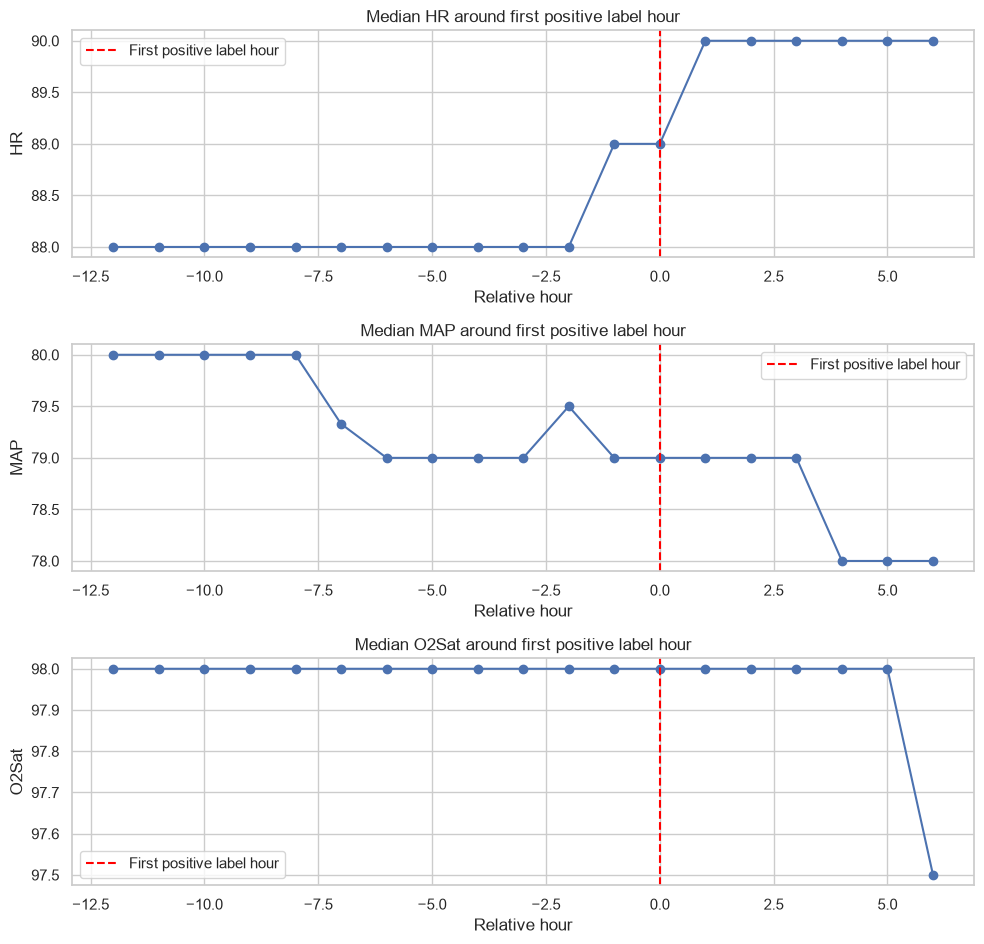

In [19]:
fig, axes = plt.subplots(len(trend_variables), 1, figsize=(10, 3.2 * len(trend_variables)))
if len(trend_variables) == 1:
    axes = [axes]

for i, col in enumerate(trend_variables):
    axes[i].plot(median_trend.index, median_trend[col], marker="o")
    axes[i].axvline(0, linestyle="--", color="red", label="First positive label hour")
    axes[i].set_title("Median " + col + " around first positive label hour")
    axes[i].set_xlabel("Relative hour")
    axes[i].set_ylabel(col)
    axes[i].legend()

plt.tight_layout()
plt.show()

### Why this makes the EDA more project-specific

A normal EDA may show only overall distributions. This chart adds the time dimension that matters in an ICU early-warning project. It lets us ask whether selected measurements show a visible change around the first positive warning label. We report the medians and sample counts, and we avoid calling the first positive label the clinical onset.

## 12. Patient record-length profile

**Question:** Do all patients contribute the same number of hourly records?

This helps us understand how much the patient record lengths vary. A patient with a longer ICU stay can contribute more rows than a patient with a shorter stay, so row-level counts are not the same as patient-level counts.

,Hourly_records_per_patient
count,40336.00
mean,38.48
std,22.80
min,8.00
25%,24.00
50%,38.00
75%,47.00
max,336.00


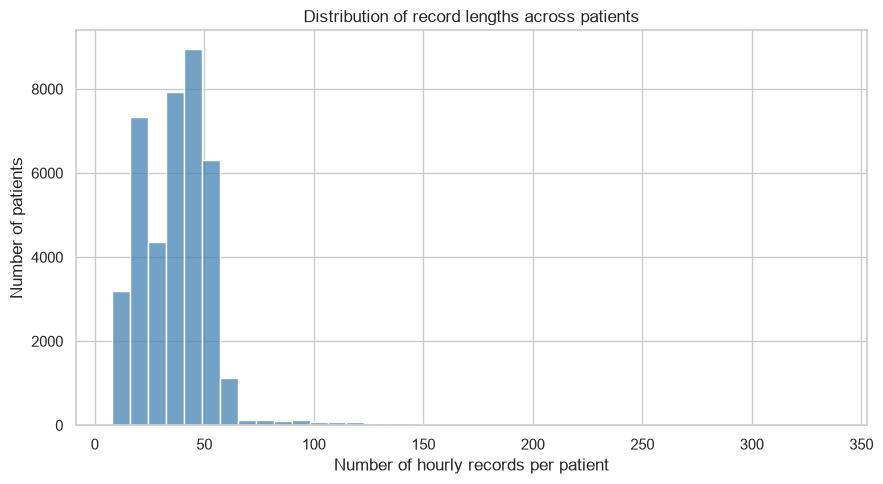

In [20]:
records_per_patient = df.groupby("Patient_ID").size()

display(records_per_patient.describe().to_frame(name="Hourly_records_per_patient").round(2))

plt.figure(figsize=(9, 5))
sns.histplot(records_per_patient, bins=40, color="steelblue")
plt.xlabel("Number of hourly records per patient")
plt.ylabel("Number of patients")
plt.title("Distribution of record lengths across patients")
plt.tight_layout()
plt.show()

## 13. Evidence-based EDA summary

This final section prints a compact set of dataset facts. Use these values to support the findings you present. Do not claim that a pattern is clinically meaningful unless you can explain what the data supports.

In [21]:
total_rows = len(df)
total_patients = df["Patient_ID"].nunique()
positive_rows = int((df["SepsisLabel"] == 1).sum())
positive_patients = int((patient_label == 1).sum())

print("===== SEPSISSHIELD: EDA SUMMARY =====")
print("Total hourly records:", f"{total_rows:,}")
print("Unique patients:", f"{total_patients:,}")
print("Positive-label hourly records:", f"{positive_rows:,}",
      f"({positive_rows / total_rows * 100:.2f}%)")
print("Patients with at least one positive label:", f"{positive_patients:,}",
      f"({positive_patients / total_patients * 100:.2f}%)")
print("Exact duplicate rows:", f"{exact_duplicates:,}")
print("Duplicate Patient_ID + Hour pairs:", f"{patient_hour_duplicates:,}")

print("\nFive variables with highest missingness:")
print(missing_table.head(5)["Missing_Percent"].round(2))

print("\nSelected vital signs with highest IQR outlier percentage:")
print(iqr_table["Outlier_Percent_of_nonmissing"].sort_values(ascending=False).head(3).round(2))

===== SEPSISSHIELD: EDA SUMMARY =====
Total hourly records: 1,552,210
Unique patients: 40,336
Positive-label hourly records: 27,916 (1.80%)
Patients with at least one positive label: 2,932 (7.27%)
Exact duplicate rows: 0
Duplicate Patient_ID + Hour pairs: 0

Five variables with highest missingness:
Bilirubin_direct    99.81
Fibrinogen          99.34
TroponinI           99.05
Bilirubin_total     98.51
Alkalinephos        98.39
Name: Missing_Percent, dtype: float64

Selected vital signs with highest IQR outlier percentage:
Variable
Resp     2.12
O2Sat    1.84
MAP      1.61
Name: Outlier_Percent_of_nonmissing, dtype: float64


## 14. Findings to take into the jury presentation

After running the notebook, write your final findings below using the actual outputs. Keep the wording evidence-based.

1. **Dataset scale:** State the number of hourly records, columns and unique patients.
2. **Target distribution:** Compare positive hourly records with patients who had at least one positive label. Explain why the two percentages differ.
3. **Missingness:** Name the variables with the highest missing percentages and describe the risk of blindly filling missing values.
4. **Measurement availability:** Identify one widely available vital sign and one less widely available laboratory measurement using the patient-coverage table.
5. **Duplicates:** Report the exact duplicate count and duplicate patient-hour count.
6. **Outliers:** Report one IQR result and explain why you flagged rather than automatically deleted it.
7. **Distributions/correlations:** Identify one visible distribution pattern or correlation, without implying causation.
8. **Temporal view:** Describe what the median trend suggests, and mention the number of available measurements and the warning-label alignment.

### Suggested closing statement

“Our EDA shows that ICU records are not simply a complete table of measurements. Observation availability differs across variables, patients contribute different numbers of hourly records, and the positive warning label is a minority class. These findings guide the preprocessing decisions and the temporal feature engineering that follow.”

---

## Scope and limitations

- This notebook performs **EDA only**. It does not clean, impute, remove outliers or engineer the final model features. Those are handled in the preprocessing and feature-engineering stages.
- IQR flags statistical outlier candidates; clinical judgement is not inferred from the IQR rule.
- Correlation does not imply causation.
- `SepsisLabel` is an early-warning label supplied by the dataset. Its first positive hour must not be described as the exact clinical onset.
- `Unit1` and `Unit2` describe ICU unit context in this dataset; they are not hospital identifiers and must not be used to claim cross-hospital validation.
- This is a retrospective academic analysis, not a clinically validated diagnostic system.

## Interactive EDA graph (Plotly)

This optional chart keeps the original Matplotlib/Seaborn analysis above unchanged. It reuses the already calculated `median_trend` table. Move the pointer over points to inspect values, zoom or pan, and use the red vertical annotation to identify the first positive `SepsisLabel` hour (relative hour 0). Each vital sign has its own panel because HR, MAP and O2Sat use different measurement scales.

If Plotly is not installed in your environment, run `pip install plotly` once.

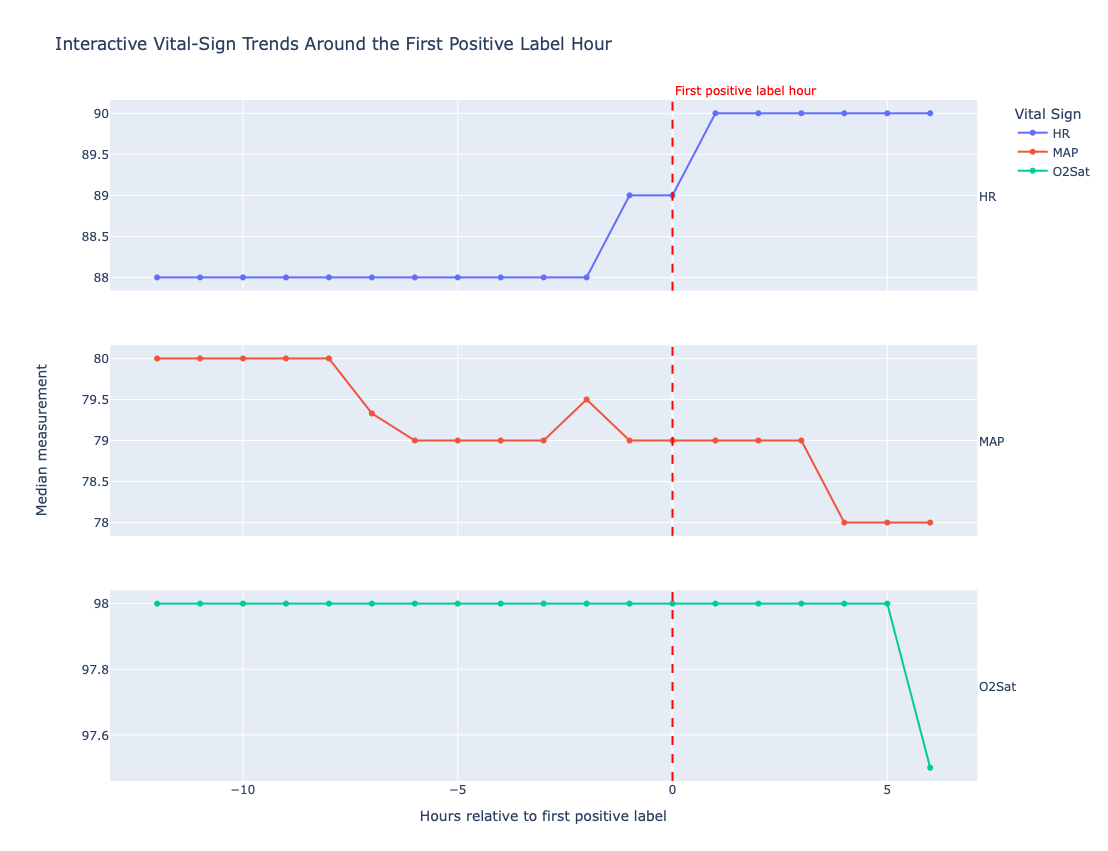

In [23]:
import plotly.express as px

plot_data = median_trend.reset_index().melt(
    id_vars="Relative_Hour",
    var_name="Vital Sign",
    value_name="Median Value"
)

fig = px.line(
    plot_data,
    x="Relative_Hour",
    y="Median Value",
    color="Vital Sign",
    facet_row="Vital Sign",
    markers=True,
    height=850,
    facet_row_spacing=0.08,
    title="Interactive Vital-Sign Trends Around the First Positive Label Hour",
    labels={
        "Relative_Hour": "Hours relative to first positive label",
        "Median Value": "Median measurement"
    }
)

# Give each vital sign its own Y-axis scale and remove repeated titles
fig.update_yaxes(matches=None, title_text="")

# Make panel labels horizontal and remove unnecessary repeated text
fig.for_each_annotation(
    lambda a: a.update(
        text=a.text.split("=")[-1],
        textangle=0
    )
)

# Draw one vertical reference line across all panels
fig.add_vline(
    x=0,
    line_dash="dash",
    line_color="red",
    line_width=2
)

# Add the reference-line annotation only once
fig.add_annotation(
    x=0,
    y=1.03,
    xref="x",
    yref="paper",
    text="First positive label hour",
    showarrow=False,
    xanchor="left",
    font=dict(color="red", size=12)
)

# Add one shared Y-axis title
fig.add_annotation(
    x=-0.09,
    y=0.5,
    xref="paper",
    yref="paper",
    text="Median measurement",
    textangle=-90,
    showarrow=False,
    font=dict(size=14)
)

fig.update_layout(
    hovermode="x unified",
    margin=dict(l=110, r=100, t=100, b=70)
)

fig.show()